# Práctico Especial — EPA Fuel Economy, Model Year 2025

**Fundamentos de la Ciencia de Datos — Cursada 2026**

Notebook única del trabajo. Está organizada en secciones que se referencian de
forma explícita en el informe, porque la cátedra las usa como guía para las
preguntas de la defensa oral.

| Sección | Contenido | Inciso del enunciado |
|---|---|---|
| 1 | Análisis exploratorio inicial de la base | 1 |
| 2 | Limpieza de la base | 2 |
| 3 | Planteo de hipótesis | 3 |
| 4 | Validación de hipótesis | 4 |

## Sección 1. Análisis exploratorio inicial de la base

### 1.1. Origen de los datos

El inciso 1 pide *investigar con recursos online el (posible) origen de los
datos*. Eso se hizo antes de abrir el archivo, y es lo que permite entender qué
es cada columna.

**Origen confirmado.** El archivo es el **"2025 Test Car List Data"**, publicado
por la *U.S. Environmental Protection Agency* (EPA) dentro del programa de
*Compliance and Fuel Economy Data*:

- Página que lo indexa:
  <https://www.epa.gov/compliance-and-fuel-economy-data/data-cars-used-testing-fuel-economy>
- Archivo publicado:
  <https://www.epa.gov/system/files/documents/2026-01/25-testcar-2026-01-21.xlsx>
- Contexto general del programa y portal oficial:
  <https://www.fueleconomy.gov/feg/download.shtml>

Tres evidencias independientes en el propio archivo confirman esa procedencia:

1. **El nombre del archivo** sigue el patrón `{año}-testcar-{fecha de publicación}.xlsx`.
   La fecha `2026-01-21` coincide con la publicación de enero de 2026 que anuncia
   la página de la EPA.
2. **Los metadatos del documento** (propiedades del `.xlsx`) identifican a
   `Danzeisen, Karen` como autora y `2026-01-21` como fecha de creación, que es el
   equipo de la EPA que prepara los archivos de prueba.
3. **El contenido de las columnas** es vocabulario del programa de ensayos de la
   EPA: `RND_ADJ_FE`, `FE Bag 1..4`, `Test Category`, `Test Vehicle ID`,
   `Drive System Description`, `Test Procedure Description`.

**Qué es este archivo.** No es una encuesta ni una muestra de vehículos vendidos.
Es el registro de los **vehículos de prueba** que la EPA ensaya en su laboratorio
de Ann Arbor (Michigan) y que los fabricantes ensayan bajo su supervisión, para
emitir las estimaciones de consumo que van en la etiqueta de cada auto. De ahí se
desprenden tres consecuencias que condicionan todo el análisis y que conviene
tener presentes desde el comienzo:

- Cada **fila no es un auto del mercado**: es una *configuración de ensayo*
  (`Test Veh Configuration #`) de un auto, medida bajo un *ciclo de prueba*
  (`Test Category`). Un mismo vehículo aparece muchas veces. Esto se cuantifica en
  la sección 1.7.
- Los valores son **estimaciones de laboratorio**, no mediciones de usuarios
  reales. No son representativos de la flota en circulación.
- Los ciclos de prueba **no son equiponderables** entre sí: miden episodios de
  conducción muy distintos (urbano, carretera, conductor agresivo).

### 1.2. Carga del dataset e inspección general

Se lee el archivo que acompaña a la notebook. El `.xlsx` de la EPA requiere
`openpyxl` como motor de lectura: sin esa librería, `read_excel` falla.

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)

In [12]:
NOMBRE_ARCHIVO = "25-testcar-2026-01-21.xlsx"


def resolver_ruta(nombre: str) -> Path:
    """Busca el archivo subiendo desde el directorio de trabajo.

    Así la notebook corre igual se abra desde JupyterLab con la carpeta `Tp Especial`
    como raíz o desde la raíz del repositorio, sin tener que editar la ruta a mano.
    """
    for base in [Path.cwd(), *Path.cwd().resolve().parents]:
        if (base / nombre).exists():
            return base / nombre
    raise FileNotFoundError(
        f"No se encontró '{nombre}' ni en {Path.cwd()} ni en sus directorios padre. "
        "El archivo de datos debe estar en el repositorio."
    )


RUTA_DATOS = resolver_ruta(NOMBRE_ARCHIVO)
print(f"Archivo cargado desde:\n{RUTA_DATOS}")

Archivo cargado desde:
/home/tomasrocha/Escritorio/Facultad/Fundamentos-de-la-ciencia-de-datos/Tp Especial/25-testcar-2026-01-21.xlsx


In [13]:
df = pd.read_excel(RUTA_DATOS, engine="openpyxl")

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Años modelo presentes: {sorted(df['Model Year'].unique())}")
print(f"Tipos de dato:\n{df.dtypes.value_counts()}")

Dimensiones: 4287 filas x 67 columnas
Años modelo presentes: [np.int64(2025)]
Tipos de dato:
str        29
float64    29
int64       9
Name: count, dtype: int64


In [14]:
df.head()

,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Engine Code,Tested Transmission Type Code,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Code,Drive System Description,Transmission Overdrive Code,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Cd,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio,Test Procedure Cd,Test Procedure Description,Test Fuel Type Cd,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,FE_UNIT,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,DT-Inertia Work Ratio Rating,DT-Absolute Speed Change Ratg,DT-Energy Economy Rating,Target Coef A (lbf),Target Coef B (lbf/mph),Target Coef C (lbf/mph**2),Set Coef A (lbf),Set Coef B (lbf/mph),Set Coef C (lbf/mph**2),Aftertreatment Device Cd,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082337,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0256,0.536,484.329,0.008,NaN,0.0089,0.0039,18.3,MPG,17.8185,17.0058,21.6199,NaN,-0.100,-0.200,-0.350,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,0,4.0,RASXV04.0AES,Car,680,8.0,177850,A,Automatic,8,Y,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,3.08,24.8,1,Not eqipped,RASX10082338,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0007,0.040,283.235,0.007,NaN,NaN,NaN,31.3,MPG,NaN,NaN,NaN,NaN,8.720,7.090,-0.420,53.24,0.2228,0.0221,5.67,0.0083,0.0221,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073957,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0156,0.150,486.750,0.011,0.0004,0.0040,NaN,18.5,MPG,17.7311,17.8284,20.4728,NaN,-0.840,-1.000,-0.380,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,0,4.0,PASXJ04.0AEX,Both,707,8.0,177950,A,Automatic,9,Y,4,4-Wheel Drive,2,Top gear ratio < 1,5500,3.27,22.0,1,Not eqipped,PASX10073958,MFR,No,NaN,NaN,NaN,NaN,3,HWFE,61,Tier 2 Cert Gasoline,HWY,0.0000,0.020,331.480,0.003,NaN,NaN,NaN,27.2,MPG,NaN,NaN,NaN,NaN,-5.030,-4.160,-1.210,60.68,-0.3286,0.0373,-4.88,-0.5318,0.0367,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,0,5.2,SASXV05.2AMV,Car,825,12.0,AM34A/,A,Automatic,8,N,R,"2-Wheel Drive, Rear",2,Top gear ratio < 1,4500,2.93,22.6,1,Not eqipped,SASX10087770,MFR,No,NaN,NaN,NaN,NaN,21,Federal fuel 2-day exhaust (w/can load),61,Tier 2 Cert Gasoline,FTP,0.0170,0.826,546.351,0.025,NaN,0.0080,0.0050,16.4,MPG,15.6150,15.5160,19.1550,NaN,1.617,0.912,0.033,49.17,0.3527,0.0226,-0.57,-0.0029,0.0128,TWC,Three-way catalyst,N,NaN,NaN,N,No averaging


El archivo tiene **4287 filas y 67 columnas**, todas del año modelo 2025. Las
columnas no son todas numéricas: hay una mezcla de identificadores, variables
técnicas del vehículo, parámetros del ensayo y valores de emisiones.

### 1.3. Caracterización de los atributos

Las 67 columnas se pueden agrupar por función dentro del ensayo:

| Grupo | Ejemplos de columnas | Naturaleza |
|---|---|---|
| Identificación del vehículo | `Vehicle Manufacturer Name`, `Represented Test Veh Model`, `Test Vehicle ID`, `Test Veh Configuration #` | texto / código |
| Características técnicas | `Equivalent Test Weight (lbs.)`, `Rated Horsepower`, `Test Veh Displacement (L)`, `# of Cylinders and Rotors`, `# of Gears`, `Axle Ratio` | numérica |
| Configuración de transmisión y tracción | `Tested Transmission Type`, `Drive System Description`, `Transmission Overdrive Desc` | categórica |
| Procedimiento y categoría de ensayo | `Test Category`, `Test Procedure Description`, `Test Fuel Type Description`, `Test Originator` | categórica |
| Resultados de consumo | `RND_ADJ_FE`, `FE_UNIT`, `FE Bag 1..4` | numérica |
| Emisiones | `THC (g/mi)`, `CO (g/mi)`, `CO2 (g/mi)`, `NOx (g/mi)`, `PM (g/mi)`, `CH4 (g/mi)`, `N2O (g/mi)` | numérica |
| Parámetros de resistencia aerodinámica y rodadura | `Target Coef A/B/C`, `Set Coef A/B/C`, `DT-*` | numérica |
| Tratamiento de gases de escape | `Aftertreatment Device Cd`, `Aftertreatment Device Desc` | categórica |

Notar que las emisiones están expresadas en **gramos por milla** y son resultado
del ensayo de emisiones, no del consumo: no son intercambiables con `RND_ADJ_FE`.
Además hay columnas que describen el vehículo una vez y otras que describen el
ensayo.

In [15]:
# Las variables categóricas que gobiernan el diseño del análisis son las que
# hay que inspeccionar una por una: sus valores definen los subconjuntos.
for columna in [
    "Test Category",
    "Test Procedure Description",
    "Test Fuel Type Description",
    "Drive System Description",
    "Tested Transmission Type",
    "Vehicle Type",
    "Test Originator",
]:
    print(f"\n=== {columna} ===")
    print(df[columna].value_counts(dropna=False).to_string())


=== Test Category ===
Test Category
FTP     1577
HWY     1340
CD       695
US06     412
SC03     263

=== Test Procedure Description ===
Test Procedure Description
HWFE                                          1340
Federal fuel 2-day exhaust (w/can load)        923
US06                                           412
Federal fuel 3-day exhaust                     341
SC03                                           263
Charge Depleting Highway                       239
Charge Depleting UDDS                          237
Cold CO                                        224
Multi-Cycle Test (MCT)                         190
CVS 75 and later (w/o can. load)                78
Charge Depleting 20 Degree F FTP                23
California fuel 2-day exhaust (w/can load)      11
Charge Depleting US06                            3
Charge Depleting SC03                            3

=== Test Fuel Type Description ===
Test Fuel Type Description
Tier 2 Cert Gasoline                             3236
Elec

In [38]:
# Resumen estadístico de las variables numéricas que la materia pide usar
# en las hipótesis (peso, potencia, cilindrada, cilindros) más el consumo.
NUMERICAS_CLAVE = [
    "RND_ADJ_FE",
    "Equivalent Test Weight (lbs.)",
    "Rated Horsepower",
    "Test Veh Displacement (L)",
    "# of Cylinders and Rotors",
]

df[NUMERICAS_CLAVE].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
RND_ADJ_FE,4066.0,64.96,456.94,0.0,24.30,32.90,43.7,10000.0
Equivalent Test Weight (lbs.),4287.0,4818.78,985.82,2750.0,4000.00,4750.00,5500.0,9000.0
Rated Horsepower,4287.0,340.70,175.12,1.0,201.00,305.00,409.0,1948.0
Test Veh Displacement (L),4287.0,4.69,14.57,0.0,1.99,2.49,3.0,100.0
# of Cylinders and Rotors,3617.0,5.22,1.62,3.0,4.00,4.00,6.0,16.0


#### 1.3.1. Las tres variables que estructuran todo el análisis

Tres columnas determinan el resto:

- **`Test Category`**: el ciclo de prueba. No tiene 2 valores sino **5**: `FTP`,
  `HWY`, `CD`, `US06` y `SC03`. `FTP` (*Federal Test Procedure*) es el ciclo
  urbano; `HWY` es el de carretera; `US06` y `SC03` son ciclos de conductor
  agresivo; y `CD` agrupa los ciclos *charge depleting* (descarga de batería) de
  los vehículos enchufables. Tomar la base completa sin filtrar mezcla cuatro
  regímenes de conducción incomparables.
- **`Test Fuel Type Description`**: el combustible. Distingue combustión
  (gasolina, diesel, etanol) de **`Electricity` (654 filas)** y **`Hydrogen 5`
  (10 filas)**. Estas últimas no son MPG sino MPGe.
- **`Drive System Description`**: la tracción. Tiene **5 categorías**, dos de las
  cuales (`All Wheel Drive` y `4-Wheel Drive`) son conceptualmente distintas y
  conviene no fundirlas sin pensarlo.

#### 1.3.2. Quién hizo cada ensayo

`Test Originator` registra quién realizó la medición, y confirma lo que dice la
documentación de la EPA: **3839 filas fueron ensayadas por el fabricante (MFR) y
448 por la propia EPA**. No es un dataset homogéneo en su origen: hay dos
protocolos ejecutados por organizaciones distintas, que conviven en la misma tabla.

`Vehicle Type` tiene un valor esperable: `Car` (1631), `Truck` (2030) y **`Both`
(626)**, que agrupa a los modelos que la EPA clasifica como auto y camioneta a la
vez. Un agregado por `Vehicle Type` mezcla categorías de tamaño y peso muy
distintos.

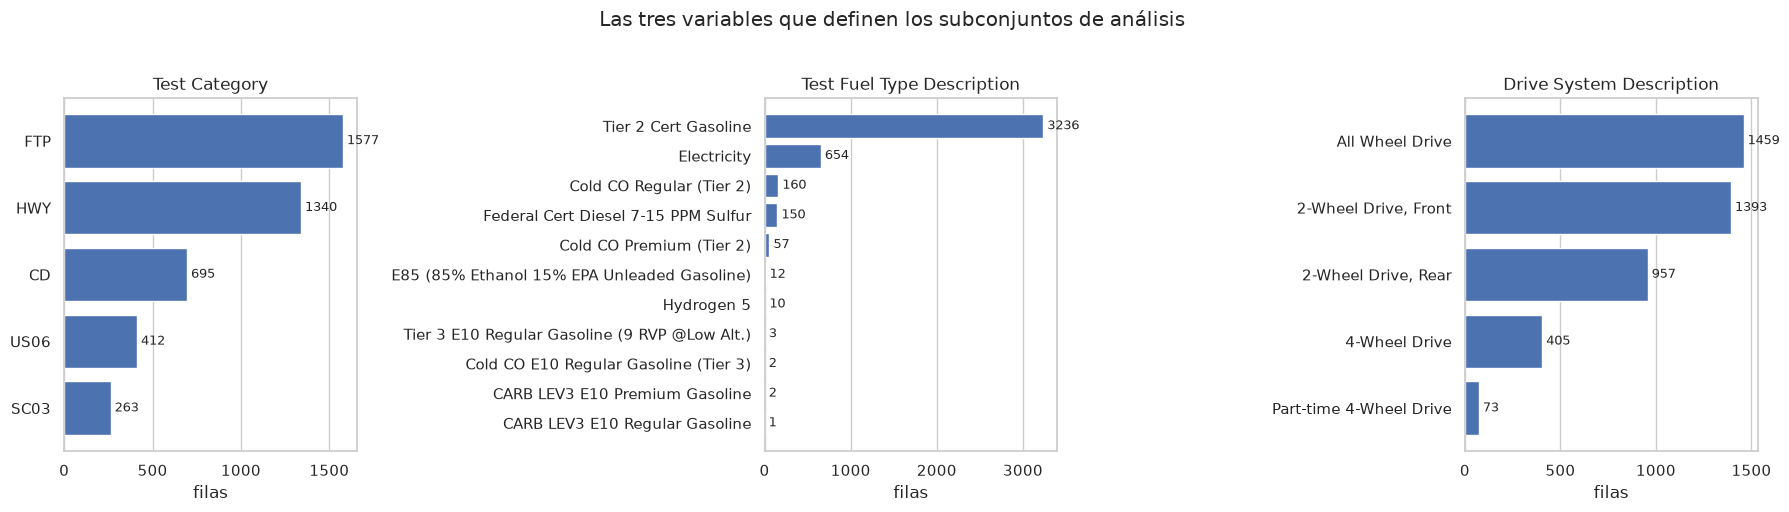

In [17]:
# Gráfico de barras de las tres variables que definen los subconjuntos.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, columna in zip(
    axes,
    ["Test Category", "Test Fuel Type Description", "Drive System Description"],
):
    conteo = df[columna].value_counts()
    ax.barh(conteo.index[::-1], conteo.values[::-1], color="#4C72B0")
    ax.set_title(columna)
    ax.set_xlabel("filas")
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(conteo.values[::-1]):
        ax.text(v, i, f" {v}", va="center", fontsize=9)

fig.suptitle("Las tres variables que definen los subconjuntos de análisis", y=1.02)
plt.tight_layout()
plt.show()

### 1.4. Comportamiento y distribución de las variables

#### 1.4.1. Consumo de combustible (`RND_ADJ_FE`)

Es la variable de interés central. Su distribución cruda está **severamente
alterada por valores centinela** (se detalla en 1.6), por lo que se la observa
de dos formas: la cruda, y la recortada a valores plausibles.

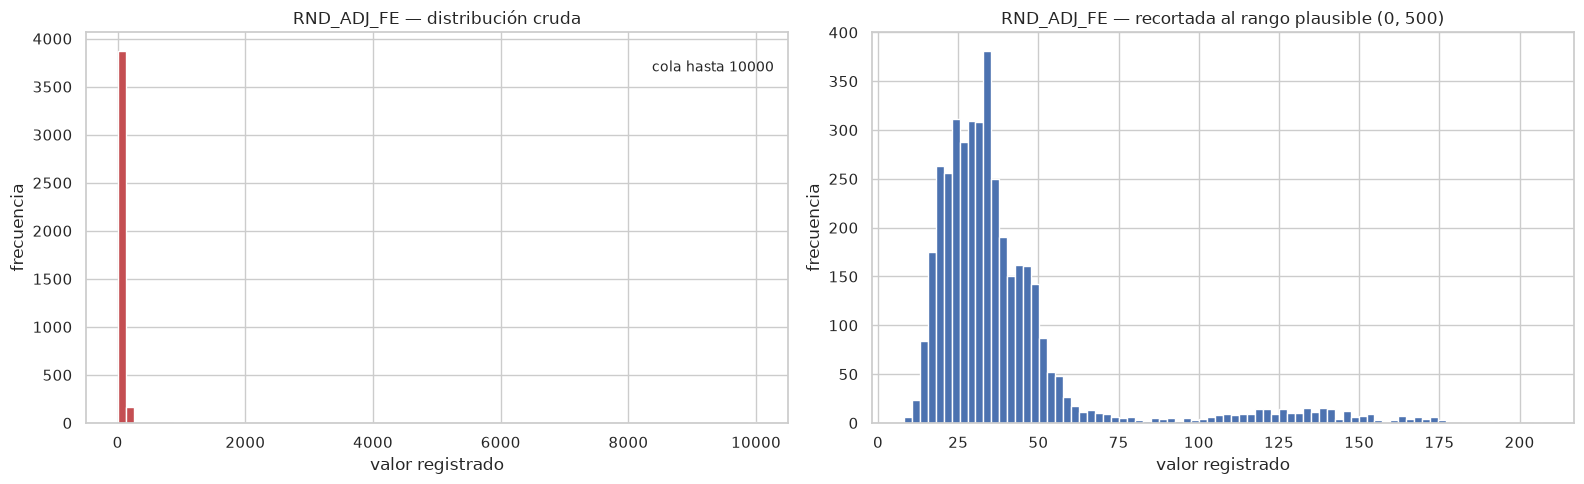

In [18]:
consumo = df["RND_ADJ_FE"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Escala completa: se ve el problema.
axes[0].hist(consumo.dropna(), bins=80, color="#C44E52", edgecolor="white")
axes[0].set_title("RND_ADJ_FE — distribución cruda")
axes[0].set_xlabel("valor registrado")
axes[0].set_ylabel("frecuencia")
axes[0].annotate(
    f"cola hasta {consumo.max():.0f}",
    xy=(0.98, 0.9),
    xycoords="axes fraction",
    ha="right",
    fontsize=10,
)

# Escala recortada a valores físicamente posibles.
plausible = consumo[(consumo > 0) & (consumo < 500)]
axes[1].hist(plausible, bins=80, color="#4C72B0", edgecolor="white")
axes[1].set_title("RND_ADJ_FE — recortada al rango plausible (0, 500)")
axes[1].set_xlabel("valor registrado")
axes[1].set_ylabel("frecuencia")

plt.tight_layout()
plt.show()

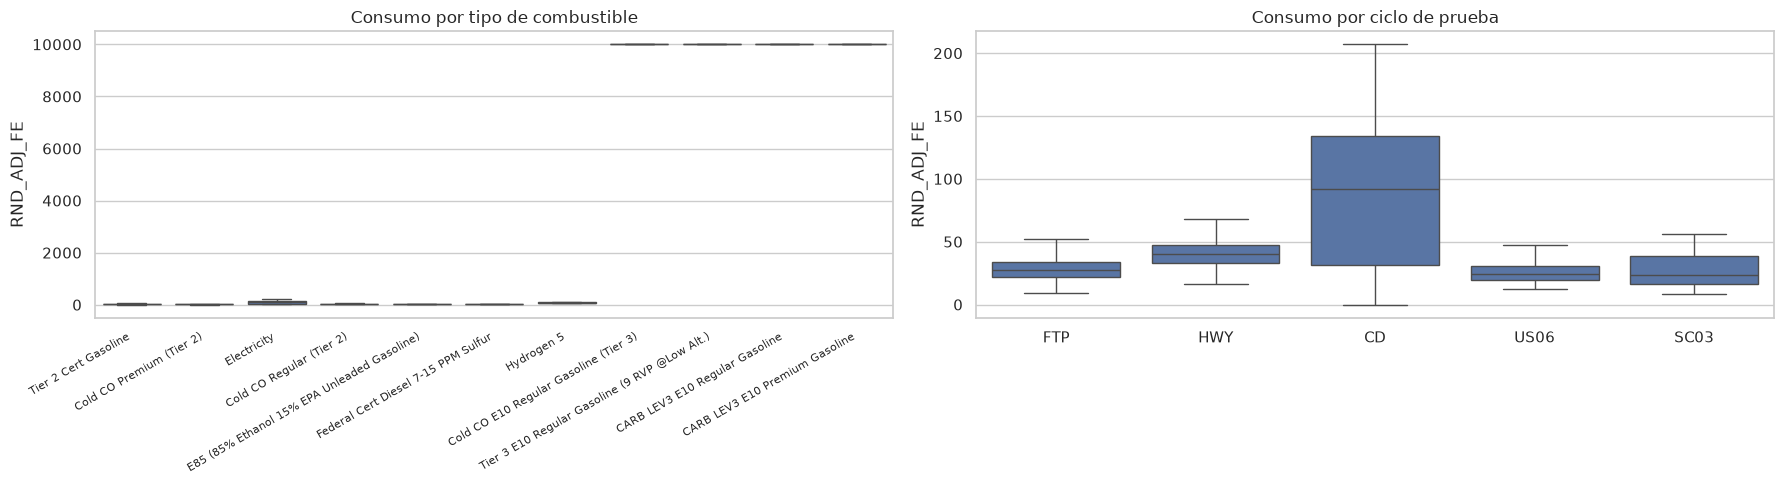

In [19]:
# El consumo según el combustible y el ciclo: aquí se ve que mezclar los datos
# no tiene sentido físico.
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.boxplot(
    data=df,
    x="Test Fuel Type Description",
    y="RND_ADJ_FE",
    ax=axes[0],
    showfliers=False,
)
# Se rotan las etiquetas ya dibujadas en vez de llamar a set_xticklabels(),
# que emite un UserWarning de seaborn al no haber un número fijo de ticks.
for etiqueta in axes[0].get_xticklabels():
    etiqueta.set_rotation(30)
    etiqueta.set_ha("right")
    etiqueta.set_fontsize(8)
axes[0].set_title("Consumo por tipo de combustible")
axes[0].set_xlabel("")
axes[0].set_ylabel("RND_ADJ_FE")

sns.boxplot(
    data=df,
    x="Test Category",
    y="RND_ADJ_FE",
    ax=axes[1],
    showfliers=False,
    order=["FTP", "HWY", "CD", "US06", "SC03"],
)
axes[1].set_title("Consumo por ciclo de prueba")
axes[1].set_xlabel("")
axes[1].set_ylabel("RND_ADJ_FE")

plt.tight_layout()
plt.show()

El boxplot por combustible muestra que `Electricity` y `Hydrogen 5` tienen escalas
incomparables: sus valores no son galones por milla. Mezclarlos en un mismo
análisis produce una media que no significa nada.

#### 1.4.2. Características técnicas

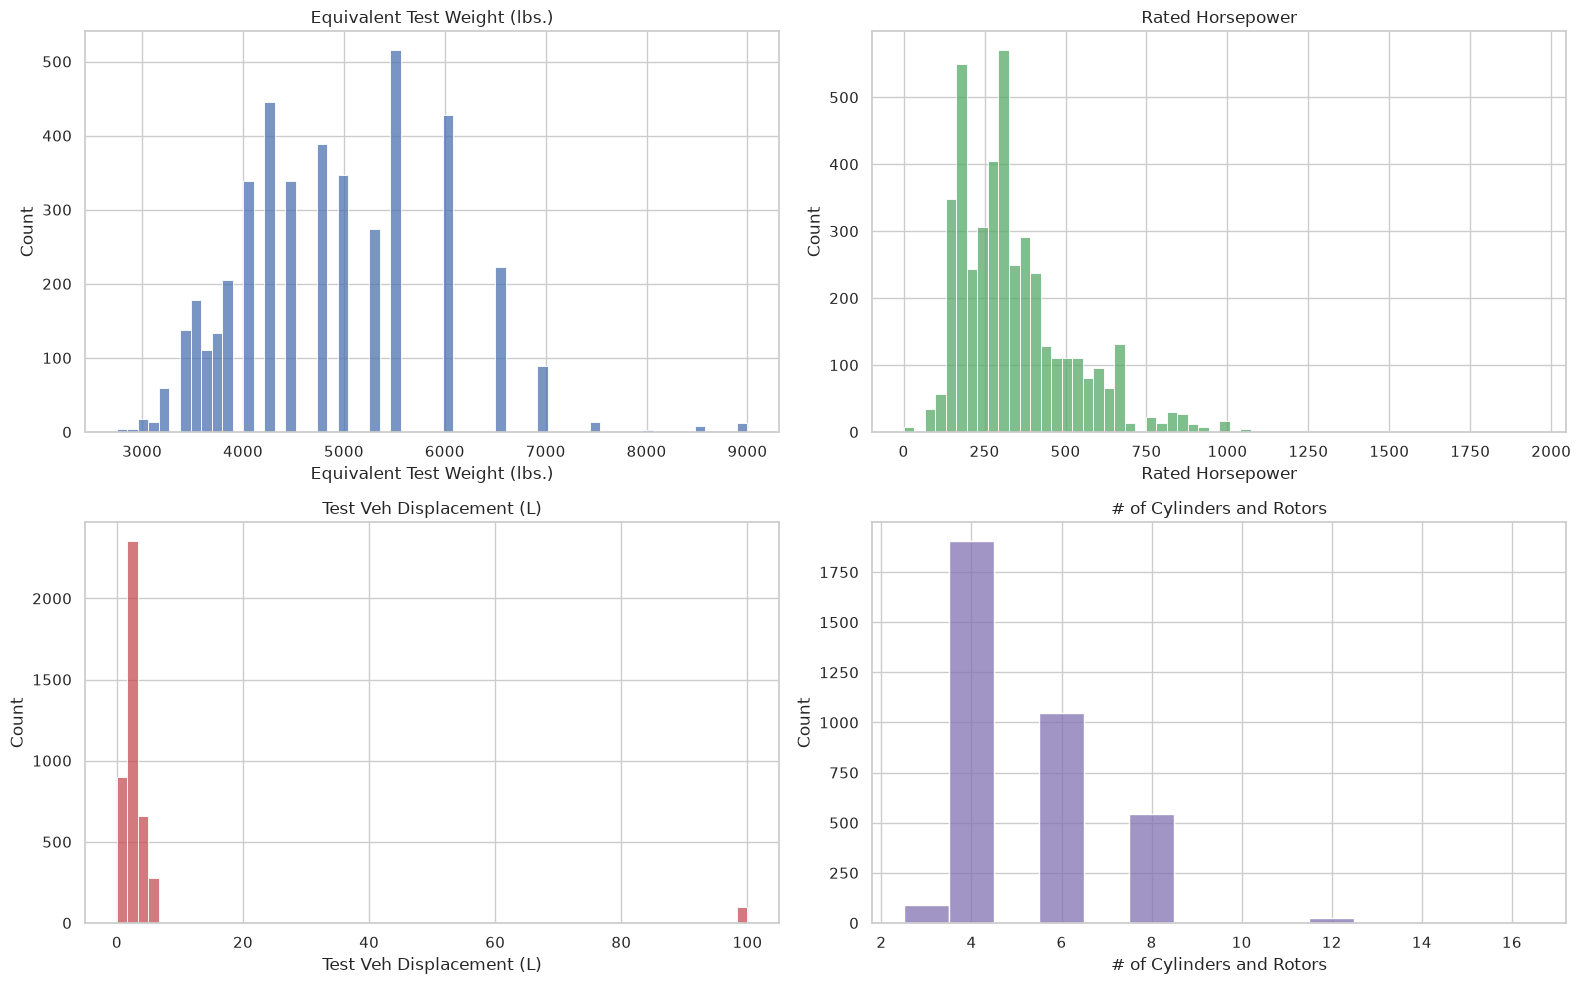

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.histplot(df["Equivalent Test Weight (lbs.)"], bins=60, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Equivalent Test Weight (lbs.)")

sns.histplot(df["Rated Horsepower"], bins=60, ax=axes[0, 1], color="#55A868")
axes[0, 1].set_title("Rated Horsepower")

sns.histplot(df["Test Veh Displacement (L)"], bins=60, ax=axes[1, 0], color="#C44E52")
axes[1, 0].set_title("Test Veh Displacement (L)")

sns.histplot(
    df["# of Cylinders and Rotors"].dropna(),
    bins=30,
    discrete=True,
    ax=axes[1, 1],
    color="#8172B2",
)
axes[1, 1].set_title("# of Cylinders and Rotors")

plt.tight_layout()
plt.show()

### 1.5. Valores nulos

El faltante es heterogéneo: hay columnas con nulos irrelevantes (parámetros de
emisiones que solo se miden en parte de los ensayos) y columnas con nulos que sí
afectan al análisis. La magnitud del problema es muy distinta según la columna.

In [21]:
nulos = pd.DataFrame(
    {
        "nulos": df.isna().sum(),
        "porcentaje": (100 * df.isna().mean()).round(1),
    }
)
nulos_con_datos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

print(f"Columnas con al menos un nulo: {len(nulos_con_datos)} de {df.shape[1]}")
nulos_con_datos

Columnas con al menos un nulo: 24 de 67


,nulos,porcentaje
Averaging Group ID,4212,98.3
Averaging Weighting Factor,4212,98.3
ADFE Test Number,4075,95.1
ADFE Total Road Load HP,4075,95.1
ADFE Equiv. Test Weight (lbs.),4075,95.1
ADFE N/V Ratio,4075,95.1
FE Bag 4,3899,90.9
PM (g/mi),3898,90.9
FE Bag 3,2834,66.1
FE Bag 1,2423,56.5


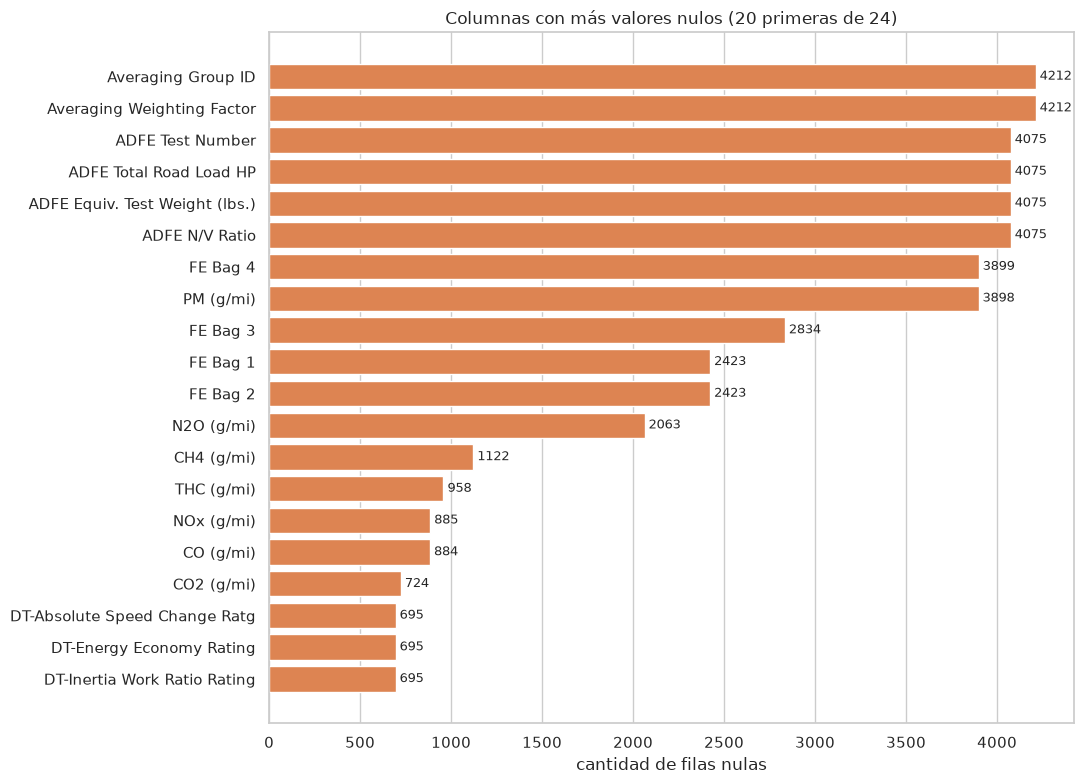

In [22]:
fig, ax = plt.subplots(figsize=(11, 8))
top = nulos_con_datos.head(20)
ax.barh(top.index[::-1], top["nulos"].values[::-1], color="#DD8452")
ax.set_xlabel("cantidad de filas nulas")
ax.set_title("Columnas con más valores nulos (20 primeras de 24)")
ax.grid(axis="y", visible=False)

for i, v in enumerate(top["nulos"].values[::-1]):
    ax.text(v, i, f" {v}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

Lecturas relevantes:

- **`RND_ADJ_FE`** tiene **221 nulos**: son filas sin consumo válido, y como se
  verá en 1.6, el conjunto de nulos se concentra fuera de los ensayos urbanos de
  combustión.
- **`# of Cylinders and Rotors`** tiene **670 nulos**, de los cuales 664 son
  justamente los vehículos eléctricos (que no tienen cilindros) y solo 6 son de
  combustión. La variable está ausente *por definición* en la mayoría de sus
  nulos.
- **`Averaging Group ID`** y **`Averaging Weighting Factor`** están vacíos en
  **4212 de 4287 filas (98 %)**: no son variables utilizables.
- `Equivalent Test Weight (lbs.)`, `Rated Horsepower` y `Test Veh Displacement (L)`
  **no tienen ningún nulo**. Ahora bien, "sin nulos" no significa "limpias": esas
  tres columnas tienen centinelas, que se tratan en 1.6.2.

In [23]:
# El nulo de RND_ADJ_FE no se distribuye al azar: hay que ver dónde se concentra.
print("Nulos de RND_ADJ_FE por ciclo de prueba:")
print(
    df.assign(falta=df["RND_ADJ_FE"].isna())
    .groupby("Test Category")["falta"]
    .agg(["sum", "size", "mean"])
    .rename(columns={"sum": "nulos", "size": "filas", "mean": "proporcion"})
    .round(3)
    .to_string()
)

Nulos de RND_ADJ_FE por ciclo de prueba:
               nulos  filas  proporcion
Test Category                          
CD               130    695       0.187
FTP               26   1577       0.016
HWY               23   1340       0.017
SC03              23    263       0.087
US06              19    412       0.046


### 1.6. Outliers y valores centinela

Esta es la particularidad más importante de la base y la que más daño hace si no
se detecta: **los valores centinela de la EPA no están registrados como nulos**.

La EPA codifica el dato faltante con un número mágico en lugar de dejarlo vacío.
Ese número aparece escrito directamente en la columna de resultados, así que
**ni `isnull()`, ni `dropna()`, ni un umbral de "faltantes" lo detectan**. En esta
base se observan cuatro valores distintos de ese tipo: `999.0`, `4595.3`,
`4599.1` y `9999.99`.

Peor aún: no siempre son centinelas. Son valores que en la base pueden ser
**cotas de truncamiento** (el valor real existe, pero quedó fuera de rango) o
**centinelas sin dato**. La diferencia importa para la limpieza y se resuelve
mirando los `FE Bag 1..4` de la misma fila.

In [24]:
consumo_valido = df["RND_ADJ_FE"].dropna()

# Un auto no rinde 999 ni 4595 galones por milla: por encima de 500 el valor
# está o truncado o es un marcador de dato faltante.
CENTINELA = 500
centinelas = df[df["RND_ADJ_FE"] > CENTINELA]

print(f"Filas con RND_ADJ_FE > {CENTINELA}: {len(centinelas)}")
print(f"Valores distintos observados: {sorted(centinelas['RND_ADJ_FE'].unique())}")
print()
print("Reparto de los centinelas por combustible y ciclo:")
print(
    centinelas.groupby(["Test Fuel Type Description", "Test Category"])
    .size()
    .to_string()
)

Filas con RND_ADJ_FE > 500: 24
Valores distintos observados: [np.float64(999.0), np.float64(4595.3), np.float64(4599.1), np.float64(9999.9999999)]

Reparto de los centinelas por combustible y ciclo:
Test Fuel Type Description                     Test Category
CARB LEV3 E10 Premium Gasoline                 FTP               1
                                               HWY               1
CARB LEV3 E10 Regular Gasoline                 SC03              1
Cold CO E10 Regular Gasoline (Tier 3)          FTP               2
Cold CO Premium (Tier 2)                       FTP               2
Electricity                                    CD               14
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)  FTP               1
                                               HWY               1
                                               SC03              1


**Cómo se confirma que son centinelas.** El cruce de evidencia está en los bags
de combustible: en la fila del **LEXUS RC F** aparece `999.0` explícito en `FE Bag
1`, `FE Bag 2` y `FE Bag 3`, que es literalmente el marcador del protocolo. En el
**Lotus Emira** en cambio los bags traen valores plausibles (17.4, 18.4, 22.2)
mientras `RND_ADJ_FE` vale `9999.99`: ahí el 9999.99 es una **cota de truncamiento**
y el dato real está disponible en los bags.

In [25]:
# El cruce que delata el protocolo: FE Bag 1..3 de las filas centinela.
centinelas_filas = df[df["RND_ADJ_FE"] > CENTINELA].copy()
centinelas_filas["bag_1"] = centinelas_filas["FE Bag 1"].round(1)

print("Filas cuyo FE Bag 1 vale 999.0 (centinela sin dato real):")
print(centinelas_filas.loc[centinelas_filas["FE Bag 1"] == 999.0,
    ["Represented Test Veh Make", "Represented Test Veh Model", "Test Category",
     "RND_ADJ_FE", "FE Bag 1", "FE Bag 2", "FE Bag 3"]].to_string(index=False))

print("\nFilas con bags plausibles pero RND_ADJ_FE centinela (dato truncado):")
print(centinelas_filas.loc[centinelas_filas["FE Bag 1"] != 999.0,
    ["Represented Test Veh Make", "Represented Test Veh Model", "Test Category",
     "RND_ADJ_FE", "FE Bag 1", "FE Bag 2", "FE Bag 3"]].head(10).to_string(index=False))

Filas cuyo FE Bag 1 vale 999.0 (centinela sin dato real):
Represented Test Veh Make Represented Test Veh Model Test Category  RND_ADJ_FE  FE Bag 1  FE Bag 2  FE Bag 3
                    LEXUS                       RC F           FTP      4595.3     999.0     999.0     999.0

Filas con bags plausibles pero RND_ADJ_FE centinela (dato truncado):
Represented Test Veh Make Represented Test Veh Model Test Category  RND_ADJ_FE  FE Bag 1  FE Bag 2  FE Bag 3
                    Lotus                      Emira           FTP     10000.0 17.431925 18.420561 22.182237
                    Lotus                      Emira          SC03     10000.0       NaN       NaN       NaN
                    Lotus                      Emira           FTP     10000.0 19.869821 17.550956 22.294415
                    Lotus                      Emira           HWY     10000.0       NaN       NaN       NaN
                    Lotus                      Emira          SC03     10000.0       NaN       NaN       NaN


Efecto de los centinelas sobre las medidas de posición y dispersión. El efecto no
es menor: **multiplica por 50 el desvío estándar** y desplaza la media.

In [26]:
recortado = consumo_valido[consumo_valido <= CENTINELA]

comparativa = pd.DataFrame(
    {
        "con centinelas": consumo_valido.describe(),
        "sin centinelas": recortado.describe(),
    }
)
comparativa.loc[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,con centinelas,sin centinelas
count,4066.00,4042.00
mean,64.96,39.82
std,456.94,28.41
min,0.00,0.00
25%,24.30,24.30
50%,32.90,32.80
75%,43.70,43.40
max,10000.00,207.00


In [27]:
# Detección sistemática de outliers por criterio IQR en las variables clave.
def outliers_por_iqr(serie, factor=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - factor * iqr, q3 + factor * iqr
    atipicos = serie[(serie < limite_inf) | (serie > limite_sup)]
    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "limite inferior": limite_inf,
        "limite superior": limite_sup,
        "n atipicos": len(atipicos),
        "% atipicos": round(100 * len(atipicos) / serie.notna().sum(), 2),
    }


filas_iqr = []
for columna in NUMERICAS_CLAVE:
    filas_iqr.append({"columna": columna, **outliers_por_iqr(df[columna].dropna())})

pd.DataFrame(filas_iqr).round(2)

,columna,Q1,Q3,IQR,limite inferior,limite superior,n atipicos,% atipicos
0,RND_ADJ_FE,24.30,43.7,19.40,-4.80,72.80,328,8.07
1,Equivalent Test Weight (lbs.),4000.00,5500.0,1500.00,1750.00,7750.00,23,0.54
2,Rated Horsepower,201.00,409.0,208.00,-111.00,721.00,141,3.29
3,Test Veh Displacement (L),1.99,3.0,1.01,0.48,4.51,995,23.21
4,# of Cylinders and Rotors,4.00,6.0,2.00,1.00,9.00,28,0.77


El criterio IQR marca una proporción de valores extremos baja en la mayoría de las
variables técnicas: son distribuciones de parámetros de ingeniería, con colas
fisiológicamente limitadas. **Ese detector, sin embargo, no alcanza**: los
centinelas de `RND_ADJ_FE` y de la cilindrada (sección 1.6.2) no son atípicos
estadísticos, son marcadores de significado distinto, y un criterio puramente
numérico no los separa de una observación válida.

#### 1.6.1. `FE_UNIT` no es informativo

`FE_UNIT` contiene el literal `'MPG'` en **las 4287 filas, sin una sola
excepción**. Para los vehículos eléctricos eso es incorrecto: la unidad es MPGe
(millas equivalentes por galón eléctrico). La columna no permite distinguir un
caso del otro y **no sirve como criterio de filtrado**.

In [28]:
print("Valores de FE_UNIT:", df["FE_UNIT"].unique())
print("Filas de combustion:", (~df["Test Fuel Type Description"].isin(["Electricity", "Hydrogen 5"])).sum())
print("Filas Electricity/Hydrogen:", df["Test Fuel Type Description"].isin(["Electricity", "Hydrogen 5"]).sum())
print()
print("FE de los eléctricos (son MPGe, no MPG):")
print(df.loc[df["Test Fuel Type Description"] == "Electricity", "RND_ADJ_FE"].describe().round(2).to_string())

Valores de FE_UNIT: <StringArray>
['MPG']
Length: 1, dtype: str
Filas de combustion: 3623
Filas Electricity/Hydrogen: 664

FE de los eléctricos (son MPGe, no MPG):
count    563.00
mean     106.25
std      151.96
min       15.20
25%       31.60
50%       92.50
75%      133.85
max      999.00


#### 1.6.2. Centinelas también en las variables técnicas

El mismo problema aparece en las variables que sostienen la hipótesis multivariada
del inciso 4.c, y es importante detectarlo **antes** de la Sección 2:

- **`Test Veh Displacement (L)` vale `99.999` (y `99.990`) en 97 filas.** Ningún
  vehículo tiene 100 litros de cilindrada. Las 97 filas son **eléctricas**: la
  EPA escribe ese valor donde no corresponde la variable, porque no hay motor de
  combustión que medir.
- **`Rated Horsepower` vale `1` en 8 filas.** Un Ford Bronco Sport de 1.5 L con
  1 caballo de potencia no existe. Las 8 filas son 6 de ese Ford a gasolina y 2
  del Toyota Mirai, que es una pila de combustible.

Es decir: estas columnas **no tienen nulos, pero sí tienen centinelas**. "No tiene
nulos" y "está limpia" son cosas distintas, y confundirlas es exactamente el error
que la cátedra penaliza.

In [29]:
# Los centinelas técnicos quedan ocultos si sólo se mira isna(): hay que mirarlos
# con criterio de dominio, porque ninguna de estas columnas tiene nulos.
cilindrada = df["Test Veh Displacement (L)"]
potencia = df["Rated Horsepower"]

sospechosas = df.loc[
    (cilindrada > 20) | (potencia <= 1),
    ["Represented Test Veh Make", "Represented Test Veh Model",
     "Test Fuel Type Description", "Test Veh Displacement (L)",
     "Rated Horsepower", "# of Cylinders and Rotors"],
]

print(f"Filas con cilindrada > 20 L o potencia <= 1: {len(sospechosas)}")
print()
print("Valores de cilindrada sospechosos:", sorted(cilindrada[cilindrada > 20].unique()))
print("Valores de potencia sospechosos   :", sorted(potencia[potencia <= 1].unique()))
print()
print("Modelos afectados:")
print(sospechosas.groupby(["Represented Test Veh Make", "Represented Test Veh Model"]).size().to_string())
print()
print("Combustibles de las filas detectadas por alguna de las dos condiciones:")
print(sospechosas["Test Fuel Type Description"].value_counts().to_string())

Filas con cilindrada > 20 L o potencia <= 1: 105

Valores de cilindrada sospechosos: [np.float64(99.99), np.float64(99.999)]
Valores de potencia sospechosos   : [np.int64(1)]

Modelos afectados:
Represented Test Veh Make  Represented Test Veh Model                        
Ford                       BRONCO SPORT 4WD                                       3
                           BRONCO SPORT SASQUATCH                                 3
NISSAN                     ARIYA ENGAGE                                           2
                           ARIYA ENGAGE e-4ORCE                                   2
                           ARIYA EVOLVE                                           2
                           ARIYA EVOLVE+e-4ORCE                                   2
                           ARIYA PLATINUM+ e-4ORCE                                4
                           LEAF                                                   4
                           LEAF SV/SL SV PLUS          

### 1.7. Estructura de la base: unidad de observación y subconjuntos de interés

La característica estructural más consecuente de esta base es que **las filas no
son observaciones independientes de una población de vehículos**.

El archivo tiene 4287 filas, pero solo **953 `Test Vehicle ID` distintos**: cada
vehículo aparece entre **1 y 45 veces** (4,50 filas de media). Las repeticiones no
son ruido ni duplicados accidentales: son **distintas configuraciones del mismo
auto ensayadas bajo distintos ciclos de prueba**.

Esto tiene una consecuencia estadística que condiciona la Sección 4: correr un test
de hipótesis tratando las 1547 filas de combustión+`FTP` como 1547 vehículos
independientes **infla la significación estadística**, porque violamos el supuesto
de independencia de las observaciones.

In [30]:
n_filas = len(df)
n_vehiculos = df["Test Vehicle ID"].nunique()

print(f"Filas: {n_filas}")
print(f"Vehículos distintos (Test Vehicle ID): {n_vehiculos}")
print(f"Filas por vehículo — promedio: {n_filas / n_vehiculos:.2f}")
print()

filas_por_vehiculo = df.groupby("Test Vehicle ID").size()
print(filas_por_vehiculo.describe().round(2).to_string())
print()
print("Distribución de filas por vehículo:")
print(filas_por_vehiculo.value_counts().sort_index().to_string())

Filas: 4287
Vehículos distintos (Test Vehicle ID): 953
Filas por vehículo — promedio: 4.50

count    953.00
mean       4.50
std        3.94
min        1.00
25%        2.00
50%        4.00
75%        6.00
max       45.00

Distribución de filas por vehículo:
1      66
2     316
3      56
4     173
5      87
6      90
7      32
8      39
9      10
10     42
11      4
12     15
13      3
14      2
15      4
16      2
17      1
18      3
20      1
21      1
25      1
32      2
34      1
45      2


In [31]:
# Un vehículo real y sus repeticiones, para que se vea qué es cada fila.
vehiculo_mas_filas = filas_por_vehiculo.idxmax()
print(f"Vehículo con más filas: {vehiculo_mas_filas} ({filas_por_vehiculo.max()} filas)\n")

df.loc[
    df["Test Vehicle ID"] == vehiculo_mas_filas,
    [
        "Represented Test Veh Make",
        "Represented Test Veh Model",
        "Test Veh Configuration #",
        "Test Category",
        "Test Procedure Description",
        "RND_ADJ_FE",
    ],
].head(25)

Vehículo con más filas: 30KPPV1970 (45 filas)



,Represented Test Veh Make,Represented Test Veh Model,Test Veh Configuration #,Test Category,Test Procedure Description,RND_ADJ_FE
1313,CHEVROLET,SILVERADO 2WD,3,FTP,CVS 75 and later (w/o can. load),29.3
1314,CHEVROLET,SILVERADO 2WD,3,FTP,CVS 75 and later (w/o can. load),29.3
1315,CHEVROLET,SILVERADO 2WD,3,FTP,CVS 75 and later (w/o can. load),29.3
1316,CHEVROLET,SILVERADO 2WD,3,HWY,HWFE,43.9
1317,CHEVROLET,SILVERADO 2WD,3,HWY,HWFE,43.9
1318,CHEVROLET,SILVERADO 2WD,3,HWY,HWFE,43.9
1319,CHEVROLET,SILVERADO 2WD,3,US06,US06,25.7
1320,CHEVROLET,SILVERADO 2WD,3,US06,US06,25.7
1321,CHEVROLET,SILVERADO 2WD,3,US06,US06,25.7
1407,CHEVROLET,SILVERADO 4WD MUD TERRAIN TIRES,5,US06,US06,22.7


El mismo auto aparece bajo `FTP`, `HWY`, `CD`, `US06` y `SC03`, con consumos
distintos en cada caso. Son **la misma unidad física medida en condiciones
distintas**, no unidades distintas.

#### 1.7.1. Los subconjuntos que pide el enunciado

Las tres hipótesis que impone la cátedra están todas referidas a **vehículos a
combustión** y la primera, además, a **conducción urbana** (`FTP`, el ciclo urbano
estadounidense). Eso define los subconjuntos de trabajo.

In [32]:
NO_COMBUSTION = ["Electricity", "Hydrogen 5"]

combustion = df[~df["Test Fuel Type Description"].isin(NO_COMBUSTION)]
combustion_ftp = combustion[combustion["Test Category"] == "FTP"]

print(f"Base completa                     : {len(df):>5} filas, {df['Test Vehicle ID'].nunique():>4} vehículos")
print(f"Combustión                        : {len(combustion):>5} filas, {combustion['Test Vehicle ID'].nunique():>4} vehículos")
print(f"Combustión + FTP (urbano)         : {len(combustion_ftp):>5} filas, {combustion_ftp['Test Vehicle ID'].nunique():>4} vehículos")
print(f"Electricidad + hidrógeno (excluidos): {len(df) - len(combustion):>5} filas")

Base completa                     :  4287 filas,  953 vehículos
Combustión                        :  3623 filas,  740 vehículos
Combustión + FTP (urbano)         :  1547 filas,  732 vehículos
Electricidad + hidrógeno (excluidos):   664 filas


In [33]:
# Conteo de configuraciones distintas dentro del subconjunto urbano de combustión.
# "Configuración" es un candidato más fino que "fila" para la unidad de análisis.
combustion_ftp_config = combustion_ftp.groupby(
    ["Test Vehicle ID", "Test Veh Configuration #"]
).ngroups

print(f"Filas de combustión+FTP                     : {len(combustion_ftp)}")
print(f"Vehículos (Test Vehicle ID)                 : {combustion_ftp['Test Vehicle ID'].nunique()}")
print(f"Pares (vehículo, configuración) distintos   : {combustion_ftp_config}")

Filas de combustión+FTP                     : 1547
Vehículos (Test Vehicle ID)                 : 732
Pares (vehículo, configuración) distintos   : 1087


In [34]:
# El volumen de filas por vehículo en el subconjunto urbano, que es donde se
# concentran las hipótesis de la cátedra.
combo = (
    combustion_ftp.groupby("Test Vehicle ID")
    .size()
    .value_counts()
    .sort_index()
)
print("Vehículos según cuántas filas aportan a combustión+FTP:")
print(combo.to_string())

Vehículos según cuántas filas aportan a combustión+FTP:
1     311
2     255
3      58
4      67
5      10
6      21
7       1
8       2
10      3
12      1
13      1
15      2


### 1.8. Síntesis de hallazgos del inciso 1

1. **Origen**: `2025 Test Car List Data` de la EPA, publicado el 21/01/2026. Son
   ensayos de laboratorio, no mediciones de usuarios ni de la flota en
   circulación.
2. **Dimensiones**: 4287 filas × 67 columnas, todas del año modelo 2025.
3. **Las filas no son independientes**: 953 vehículos distintos para 4287 filas
   (entre 1 y 45 filas por vehículo, 4,50 de media). La unidad de análisis debe
   declararse y justificarse antes de testear.
4. **`Test Category` tiene 5 valores**, no 2. `FTP` es el urbano; mezclar ciclos
   compara consumos de episodios de conducción distintos.
5. **664 filas no son de combustión** (654 `Electricity` + 10 `Hydrogen 5`) y su
   FE está en otra unidad, aunque `FE_UNIT` diga `'MPG'` en las 4287 filas.
6. **`RND_ADJ_FE` contiene 24 centinelas de la EPA que no son nulos** (`999.0`,
   `4595.3`, `4599.1`, `9999.99`), de los cuales 6 están en combustión+`FTP`.
   Ninguna detección de faltantes los ve. Su presencia multiplica por 50 el desvío
   estándar.
7. **El faltante es heterogéneo**: 221 nulos en `RND_ADJ_FE`, 670 en
   `# of Cylinders and Rotors` (664 de ellos son los eléctricos), 4212 en
   `Averaging Group ID` (98 % vacío, inservible).
8. **Las variables técnicas son las mejor pobladas**, pero tampoco están limpias:
   no tienen nulos y sí tienen centinelas. La cilindrada vale `99.999` L en 97
   filas (todas eléctricas, que no tienen motor) y la potencia vale `1` en 8
   filas (6 de un Ford Bronco Sport a gasolina y 2 del Toyota Mirai a hidrógeno).
   Son las variables que sostienen la hipótesis multivariada del inciso 4.c, así
   que el problema cae justo sobre la que más importa.

**Lo que esto obliga a hacer en la Sección 2**, y que hay que justificar acción por
acción: filtrar por combustible y por ciclo de prueba, tratar los centinelas como
faltantes aunque no figuren como tales, y fijar de forma explícita la unidad de
análisis.

---

## Sección 2. Limpieza de la base

*Pendiente — acciones correctivas justificadas una por una.*

## Sección 3. Planteo de hipótesis

*Pendiente — una hipótesis univariada, una bivariada y una multivariada, cada una
justificada con conocimiento del dominio.*

## Sección 4. Validación de hipótesis

*Pendiente — validación de las tres hipótesis propias y de las tres que impone la
cátedra, justificando la elección de cada técnica y los supuestos verificados.*